In [ ]:
# Clone the repo
!git clone --recursive https://github.com/microsoft/BitNet.git

%cd BitNet
!pip install -q -r requirements.txt


Cloning into 'BitNet'...
remote: Enumerating objects: 432, done.
remote: Total 432 (delta 0), reused 0 (delta 0), pack-reused 432 (from 1)
Receiving objects: 100% (432/432), 8.12 MiB | 5.27 MiB/s, done.
Resolving deltas: 100% (196/196), done.
Submodule '3rdparty/llama.cpp' (https://github.com/Eddie-Wang1120/llama.cpp.git) registered for path '3rdparty/llama.cpp'
Cloning into '/content/BitNet/3rdparty/llama.cpp'...
remote: Enumerating objects: 25639, done.        
remote: Total 25639 (delta 0), reused 0 (delta 0), pack-reused 25639 (from 1)        
Receiving objects: 100% (25639/25639), 59.72 MiB | 10.85 MiB/s, done.
Resolving deltas: 100% (18205/18205), done.
Submodule path '3rdparty/llama.cpp': checked out '1f86f058de0c3f4098dedae2ae8653c335c868a1'
Submodule 'kompute' (https://github.com/nomic-ai/kompute.git) registered for path '3rdparty/llama.cpp/ggml/src/kompute'
Cloning into '/content/BitNet/3rdparty/llama.cpp/ggml/src/kompute'...
remote: Enumerating objects: 9122, done.        
r

In [ ]:

%cd gpu
!pip install -q -r requirements.txt

/content/BitNet/gpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 129.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.7/530.7 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 155.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━

In [ ]:

!pip install -q --upgrade torch torchvision torchaudio

#################### Then RESTART Runtime ################################################################

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 152.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 85.5 MB/s eta 0:00:00


In [ ]:
cu_file_path = '/content/BitNet/gpu/bitnet_kernels/bitnet_kernels.cu'

new_entries = """
    else if (M == 1 && N == 512 && K == 800){
        ladder_int8xint2_kernel<1, 512, 800, 1, 8, 16><<<dim3(32, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 256 && K == 512){
        ladder_int8xint2_kernel<1, 256, 512, 1, 8, 16><<<dim3(16, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 128 && K == 256){
        ladder_int8xint2_kernel<1, 128, 256, 1, 8, 16><<<dim3(8, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }
    else if (M == 1 && N == 32 && K == 128){
        ladder_int8xint2_kernel<1, 32, 128, 1, 8, 16><<<dim3(2, 1, 1), dim3(8, 16, 1), 0, stream>>>(input0, input1, output0, s, ws);
    }"""

with open(cu_file_path, 'r') as f:
    content = f.read()

old_else = '    else{\n        std::cout << "required ladder gemm kernel'
new_content = content.replace(old_else, new_entries + '\n' + old_else)

with open(cu_file_path, 'w') as f:
    f.write(new_content)


In [ ]:
# Need to be using a GPU Runtime here


%cd BitNet/gpu/bitnet_kernels
!bash compile.sh
%cd ..

/content/BitNet/gpu/bitnet_kernels
/content/BitNet/gpu


In [ ]:
import os
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using {device} device")

using cuda device


In [ ]:

import torchvision
import torchvision.transforms as transforms

BATCH_SIZE = 512

# Calculate per pixel mean and std
raw = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
loader = torch.utils.data.DataLoader(raw, batch_size=60000)
images, _ = next(iter(loader))

mean = images.mean()
std  = images.std()

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean,), (std,))
])

full_train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Use some of the training data as a validation set
train_dataset, validation_dataset = torch.utils.data.random_split(full_train_dataset, [50000, 10000], generator=torch.Generator().manual_seed(993))

print(f"\nTraining samples: {len(train_dataset)}")
print(f"Validation samples: {len(test_dataset)}")
print(f"Test samples: {len(test_dataset)}")

# Create data loaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# # Visualize samples
# fig, axes = plt.subplots(2, 5, figsize=(12, 5))
# for i, ax in enumerate(axes.flat):
#     img, label = train_dataset[i]
#     ax.imshow(img.squeeze(), cmap='gray')
#     ax.set_title(f'Label: {label}')
#     ax.axis('off')
# plt.tight_layout()
# plt.show()

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.66MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.27MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.47MB/s]



Training samples: 50000
Validation samples: 10000
Test samples: 10000


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

import sys
path = '/content/BitNet/gpu'
if path not in sys.path:
  sys.path.append(path)


def RMSNorm(x, eps=1e-5):
    return x / torch.sqrt(x.pow(2).mean(dim=-1, keepdim=True) + eps)

def activation_quant(x):
  scale = 127.0 / x.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
  y = (x * scale).round().clamp_(-128,127) / scale
  return y

def weight_quant(w):
  scale = 1.0 / w.abs().mean().clamp_(min=1e-5)
  u = (w * scale).round().clamp_(-1,1) / scale
  return u

class BitLinear(nn.Linear):
  def forward(self,x):
    w = self.weight
    x_norm = RMSNorm(x)
    x_quant = x_norm + (activation_quant(x_norm) - x_norm).detach()
    w_quant = w + (weight_quant(w) - w).detach()
    y = F.linear(x_quant,w_quant)
    return y


class BitLinearModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.NN_layout = nn.Sequential(
        nn.Flatten(),

        nn.ConstantPad1d((0,16),0), #784 -> 800

        BitLinear(800,512, bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinear(512,256,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinear(256,128,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        # Output Layer
        # again, we need the output to have a certain shape. we keep the 10 neurons we want using the forward method and the rest is wasted capacity
        BitLinear(128,32,bias=False)
    )

  def forward(self, x):

    return self.NN_layout(x)[:,:10]

class BaselineModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.NN_layout = nn.Sequential(


        nn.Flatten(),

        nn.ConstantPad1d((0,16),0), #784 -> 800 Permenantly wasted capacity that has no impact on accuracy. Done just to match the BitLinear model

        nn.Linear(800,512,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        nn.Linear(512,256,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        nn.Linear(256,128,bias=False),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        # Output Layer
        nn.Linear(128,32,bias=False)

    )

  def forward(self, x):
    return self.NN_layout(x)[:,:10]


#This is the output of compiling the bitnet kernel above.
import ctypes
bitnet_lib = ctypes.CDLL('bitnet_kernels/libbitnet.so')


def bitnet_int8xint2_linear(input0, input1, s, ws):
    out_shape = list(input0.shape)
    out_shape[-1] = input1.shape[0]

    N = input1.shape[0]
    K = input1.shape[1] * 4
    M = input0.shape[0]

    ret = torch.zeros(*out_shape, dtype=torch.bfloat16, device=input0.device)
    s = s.to(torch.bfloat16).contiguous()

    streams = [torch.cuda.Stream() for _ in range(M)] # we create 512 cuda streams such that stream i+1 doesnt have to wait for stream i to finish.

    for i in range(M):
        with torch.cuda.stream(streams[i]):
            row = input0[i:i+1].contiguous()
            scale = s[i:i+1].contiguous()
            bitnet_lib.bitlinear_int8xint2(
                *[ctypes.c_void_p(row.data_ptr()),
                  ctypes.c_void_p(input1.data_ptr()),
                  ctypes.c_void_p(ret[i:i+1].data_ptr()),
                  ctypes.c_void_p(scale.data_ptr()),
                  ctypes.c_void_p(ws.data_ptr()),
                  ctypes.c_int(1),
                  ctypes.c_int(N),
                  ctypes.c_int(K),
                  ctypes.c_void_p(streams[i].cuda_stream)]
            )

    torch.cuda.synchronize()
    return ret


class BitLinearKernel(nn.Module):
    in_features: int
    out_features: int
    weight: torch.Tensor
    weight_scale: torch.Tensor

    def __init__(self, in_features: int, out_features: int, bias: bool = False):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        self.weight = torch.nn.Parameter(torch.zeros(out_features, in_features//4, dtype=torch.int8), requires_grad=False)
        self.weight_scale = torch.nn.Parameter(torch.zeros(4, dtype=torch.bfloat16), requires_grad=False)

    def quant_input(self, input):
        s = 127 / input.abs().max(dim=-1, keepdim=True).values.clamp_(min=1e-5)
        return (input * s).round().clamp(-128, 127).to(torch.int8), s

    def forward(self, input):
        input = RMSNorm(input)

        input, s = self.quant_input(input)
        return bitnet_int8xint2_linear(input, self.weight, s, self.weight_scale)


class InferenceKernel(nn.Module):
  def __init__(self):
    super().__init__()
    self.NN_layout = nn.Sequential(
        nn.Flatten(),

        nn.ConstantPad1d((0,16),0), #784 -> 800

        BitLinearKernel(800,512),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinearKernel(512,256),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        BitLinearKernel(256,128),
        nn.ReLU(),
        nn.Dropout(p=0.25),

        # Output Layer
        # again, we need the output to have a certain shape for quantization purposes. we keep the 10 neurons we want using the forward method and the rest is wasted capacity
        BitLinearKernel(128,32)
    )

  def forward(self,x):
    return self.NN_layout(x)[:,:10]



In [ ]:
# Baseline Model Testing

from tqdm import tqdm
import time
import numpy as np
import random

NUM_EPOCHS = 50
LEARNING_RATE = .001
NUM_RUNS = 3

run_times = []
run_final_accs = []
run_epochs_to_threshold = []
all_histories = []


def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

for run in range(NUM_RUNS):
    set_seed(run)
    print(f"\n{'='*40}")
    print(f"Run {run+1}/{NUM_RUNS}")
    print(f"{'='*40}")

    def init_weights(m):
        if hasattr(m, 'bias') and m.bias is not None:
            m.bias.data.zero_()
        for param in m.parameters():
            if param.dim() > 1:
                torch.nn.init.normal_(param, mean=0.0, std=0.01)

    baseline_model = BaselineModel().to(device)
    baseline_model.apply(init_weights)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        baseline_model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = baseline_model(batch)
            optimizer.zero_grad()

            loss = loss_fn(output, labels)
            train_loss += loss.detach()

            loss.backward()
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        baseline_model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = baseline_model(batch)
                loss = loss_fn(output, labels)

                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)



    torch.cuda.synchronize()
    end = time.time()

    run_times.append(end - start)
    run_final_accs.append(history['val_acc'][-1])

    # 90% threshold
    final_acc = history['val_acc'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = NUM_EPOCHS  # default to max if never reached
    for epoch, acc in enumerate(history['val_acc']):
        if acc >= threshold:
            epochs_to_threshold = epoch + 1
            break
    run_epochs_to_threshold.append(epochs_to_threshold)

    all_histories.append(history)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_times[-1]:.2f}s")
    print(f"  Final accuracy: {run_final_accs[-1]:.4f}")
    print(f"  Epochs to 90% threshold: {epochs_to_threshold}")

    # save last run
    torch.save(baseline_model.state_dict(), f'/content/baseline_run{run}.pth')


print(f"\n{'='*40}")
print(f"BASELINE SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time:          {np.mean(run_times):.2f}s ± {np.std(run_times):.2f}s")
print(f"Final accuracy:         {np.mean(run_final_accs):.4f} ± {np.std(run_final_accs):.4f}")
print(f"Epochs to 90% threshold: {np.mean(run_epochs_to_threshold):.1f} ± {np.std(run_epochs_to_threshold):.1f}")


Run 1/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.49it/s]



Run 1 results:
  Time: 645.44s
  Final accuracy: 0.9801
  Epochs to 90% threshold: 1

Run 2/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.40it/s]



Run 2 results:
  Time: 646.39s
  Final accuracy: 0.9820
  Epochs to 90% threshold: 1

Run 3/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.58it/s]


Run 3 results:
  Time: 647.63s
  Final accuracy: 0.9822
  Epochs to 90% threshold: 1

BASELINE SUMMARY (3 runs)
Training time:          646.48s ± 0.90s
Final accuracy:         0.9814 ± 0.0009
Epochs to 90% threshold: 1.0 ± 0.0


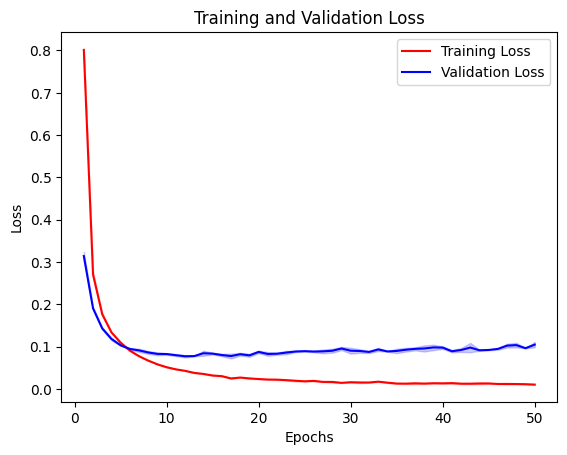

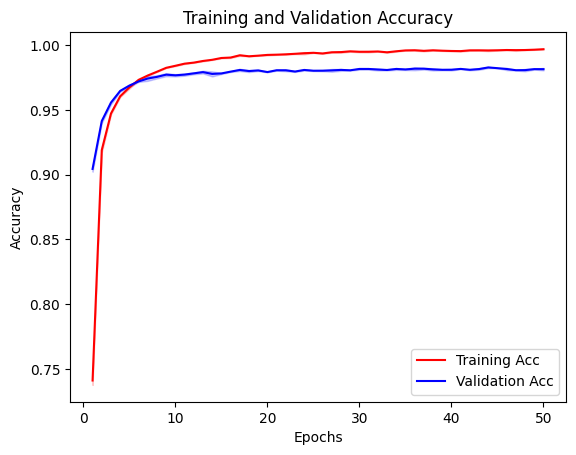

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# collect all histories
all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Shaded region shows the variance, wider = more variance

In [ ]:
def warmup_gpu(model, dataloader, num_batches=5):
    model.eval()
    with torch.no_grad():
        for i, (batch, _) in enumerate(dataloader):
            if i >= num_batches:
                break
            batch = batch.to(device)
            _ = model(batch)
    torch.cuda.synchronize()
    print(f"GPU warmup complete ({num_batches} batches)")




In [ ]:
#baseline inference
NUM_EVAL_RUNS = 3

eval_times_baseline = []
eval_losses_baseline = []
eval_accs_baseline = []
eval_latencies_baseline = []
eval_throughputs_baseline = []

for run in range(NUM_EVAL_RUNS):
    baseline_model = BaselineModel().to(device)
    baseline_model.load_state_dict(torch.load(f'/content/baseline_run{run}.pth'))
    baseline_model.eval()

    if run == 0:
        warmup_gpu(baseline_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Baseline Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = baseline_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_baseline.append(run_time)
    eval_losses_baseline.append(test_loss / len(test_loader))
    eval_accs_baseline.append(test_correct_predictions / test_total)
    eval_latencies_baseline.append(run_time / len(test_loader) * 1000)
    eval_throughputs_baseline.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_baseline[-1]:.4f}, Accuracy={eval_accs_baseline[-1]:.4f}, Latency={eval_latencies_baseline[-1]:.2f}ms, Throughput={eval_throughputs_baseline[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BASELINE INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_baseline):.2f}s ± {np.std(eval_times_baseline):.2f}s")
print(f"Loss:       {np.mean(eval_losses_baseline):.4f} ± {np.std(eval_losses_baseline):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_baseline):.4f} ± {np.std(eval_accs_baseline):.4f}")
print(f"Latency:    {np.mean(eval_latencies_baseline):.2f}ms ± {np.std(eval_latencies_baseline):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_baseline):.2f} ± {np.std(eval_throughputs_baseline):.2f} samples/s")

GPU warmup complete (5 batches)


Baseline Testing run 1/3: 100%|██████████| 20/20 [00:02<00:00,  9.41it/s]


Run 1: Time=2.13s, Loss=0.0967, Accuracy=0.9820, Latency=106.32ms, Throughput=4702.82 samples/s


Baseline Testing run 2/3: 100%|██████████| 20/20 [00:02<00:00,  9.46it/s]


Run 2: Time=2.12s, Loss=0.0889, Accuracy=0.9824, Latency=105.76ms, Throughput=4727.53 samples/s


Baseline Testing run 3/3: 100%|██████████| 20/20 [00:02<00:00,  9.40it/s]

Run 3: Time=2.13s, Loss=0.0954, Accuracy=0.9822, Latency=106.55ms, Throughput=4692.73 samples/s

BASELINE INFERENCE SUMMARY (3 runs)
Time:       2.12s ± 0.01s
Loss:       0.0937 ± 0.0034
Accuracy:   0.9822 ± 0.0002
Latency:    106.21ms ± 0.33ms
Throughput: 4707.69 ± 14.62 samples/s


In [ ]:
# Bitlinear training
from tqdm import tqdm
import numpy as np

NUM_EPOCHS = 50
LEARNING_RATE = .001
NUM_RUNS = 3

def init_weights(m):
    if hasattr(m, 'bias') and m.bias is not None:
        m.bias.data.zero_()
    for param in m.parameters():
        if param.dim() > 1:
            torch.nn.init.normal_(param, mean=0.0, std=0.01)

run_times = []
run_final_accs = []
run_epochs_to_threshold = []
all_histories = []

for run in range(NUM_RUNS):
    set_seed(run)

    print(f"\n{'='*40}")
    print(f"Run {run+1}/{NUM_RUNS}")
    print(f"{'='*40}")

    bitlinear_model = BitLinearModel().to(device)
    bitlinear_model.apply(init_weights)

    loss_fn = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(bitlinear_model.parameters(), lr=LEARNING_RATE)

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    torch.cuda.synchronize()
    start = time.time()

    for i in range(NUM_EPOCHS):
        # Training Phase
        bitlinear_model.train()
        train_loss = 0
        train_correct_predictions = 0
        train_total = 0

        for batch, labels in tqdm(train_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Training'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = bitlinear_model(batch)
            optimizer.zero_grad()

            loss = loss_fn(output, labels)
            train_loss += loss.detach()

            loss.backward()
            optimizer.step()

            predictions = torch.argmax(output, dim=1)
            train_correct_predictions += (predictions == labels).sum()
            train_total += len(labels)

        train_loss = train_loss.cpu().item() / len(train_loader)
        train_acc = train_correct_predictions.cpu().item() / train_total

        # Validation Phase
        bitlinear_model.eval()
        val_loss = 0
        val_correct_predictions = 0
        val_total = 0

        with torch.no_grad():
            for batch, labels in tqdm(val_loader, desc=f'Epoch {i + 1}/{NUM_EPOCHS} Validation'):
                batch = batch.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                output = bitlinear_model(batch)
                loss = loss_fn(output, labels)

                val_loss += loss.detach()

                predictions = torch.argmax(output, dim=1)
                val_correct_predictions += (predictions == labels).sum()
                val_total += len(labels)

        val_loss = val_loss.cpu().item() / len(val_loader)
        val_acc = val_correct_predictions.cpu().item() / val_total

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    torch.cuda.synchronize()
    end = time.time()

    run_times.append(end - start)
    run_final_accs.append(history['val_acc'][-1])
    all_histories.append(history)

    # 90% threshold
    final_acc = history['val_acc'][-1]
    threshold = 0.9 * final_acc
    epochs_to_threshold = NUM_EPOCHS
    for epoch, acc in enumerate(history['val_acc']):
        if acc >= threshold:
            epochs_to_threshold = epoch + 1
            break
    run_epochs_to_threshold.append(epochs_to_threshold)

    print(f"\nRun {run+1} results:")
    print(f"  Time: {run_times[-1]:.2f}s")
    print(f"  Final accuracy: {run_final_accs[-1]:.4f}")
    print(f"  Epochs to 90% threshold: {epochs_to_threshold}")

    torch.save(bitlinear_model.state_dict(), f'/content/unquantized_run{run}.pth')


print(f"\n{'='*40}")
print(f"BITLINEAR SUMMARY ({NUM_RUNS} runs)")
print(f"{'='*40}")
print(f"Training time:           {np.mean(run_times):.2f}s ± {np.std(run_times):.2f}s")
print(f"Final accuracy:          {np.mean(run_final_accs):.4f} ± {np.std(run_final_accs):.4f}")
print(f"Epochs to 90% threshold: {np.mean(run_epochs_to_threshold):.1f} ± {np.std(run_epochs_to_threshold):.1f}")


Run 1/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.32it/s]



Run 1 results:
  Time: 673.68s
  Final accuracy: 0.9792
  Epochs to 90% threshold: 1

Run 2/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.26it/s]



Run 2 results:
  Time: 668.12s
  Final accuracy: 0.9793
  Epochs to 90% threshold: 1

Run 3/3


Epoch 50/50 Validation: 100%|██████████| 20/20 [00:02<00:00,  9.19it/s]


Run 3 results:
  Time: 669.51s
  Final accuracy: 0.9797
  Epochs to 90% threshold: 1

BITLINEAR SUMMARY (3 runs)
Training time:           670.43s ± 2.36s
Final accuracy:          0.9794 ± 0.0002
Epochs to 90% threshold: 1.0 ± 0.0


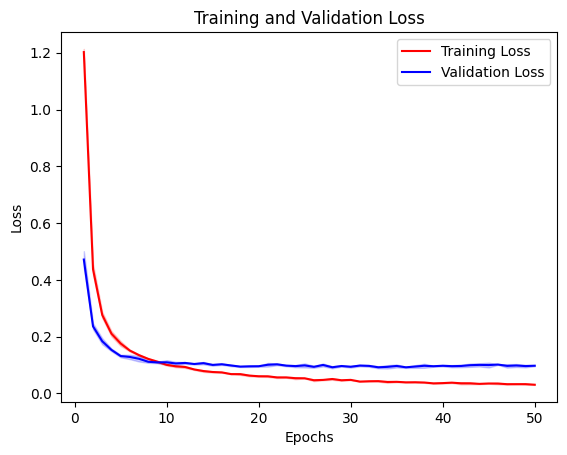

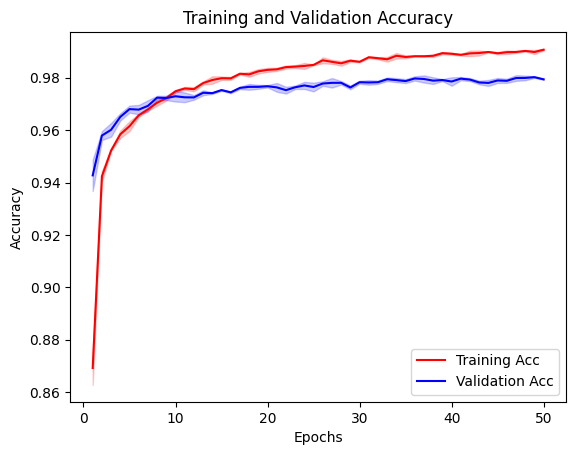

In [ ]:

all_train_loss = np.array([h['train_loss'] for h in all_histories])
all_val_loss = np.array([h['val_loss'] for h in all_histories])
all_train_acc = np.array([h['train_acc'] for h in all_histories])
all_val_acc = np.array([h['val_acc'] for h in all_histories])

epochs = np.arange(1, NUM_EPOCHS + 1)

plt.figure()
plt.plot(epochs, all_train_loss.mean(axis=0), label='Training Loss', color='red')
plt.fill_between(epochs,
                 all_train_loss.mean(axis=0) - all_train_loss.std(axis=0),
                 all_train_loss.mean(axis=0) + all_train_loss.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_loss.mean(axis=0), label='Validation Loss', color='blue')
plt.fill_between(epochs,
                 all_val_loss.mean(axis=0) - all_val_loss.std(axis=0),
                 all_val_loss.mean(axis=0) + all_val_loss.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

plt.figure()
plt.plot(epochs, all_train_acc.mean(axis=0), label='Training Acc', color='red')
plt.fill_between(epochs,
                 all_train_acc.mean(axis=0) - all_train_acc.std(axis=0),
                 all_train_acc.mean(axis=0) + all_train_acc.std(axis=0),
                 alpha=0.2, color='red')
plt.plot(epochs, all_val_acc.mean(axis=0), label='Validation Acc', color='blue')
plt.fill_between(epochs,
                 all_val_acc.mean(axis=0) - all_val_acc.std(axis=0),
                 all_val_acc.mean(axis=0) + all_val_acc.std(axis=0),
                 alpha=0.2, color='blue')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# bitlinear inference
eval_times_bitlinear = []
eval_losses_bitlinear = []
eval_accs_bitlinear = []
eval_latencies_bitlinear = []
eval_throughputs_bitlinear = []

for run in range(NUM_EVAL_RUNS):
    bitlinear_model = BitLinearModel().to(device)
    bitlinear_model.load_state_dict(torch.load(f'/content/unquantized_run{run}.pth'))
    bitlinear_model.eval()

    if run == 0:
        warmup_gpu(bitlinear_model, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'BitLinear Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = bitlinear_model(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_bitlinear.append(run_time)
    eval_losses_bitlinear.append(test_loss / len(test_loader))
    eval_accs_bitlinear.append(test_correct_predictions / test_total)
    eval_latencies_bitlinear.append(run_time / len(test_loader) * 1000)
    eval_throughputs_bitlinear.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_bitlinear[-1]:.4f}, Accuracy={eval_accs_bitlinear[-1]:.4f}, Latency={eval_latencies_bitlinear[-1]:.2f}ms, Throughput={eval_throughputs_bitlinear[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"BITLINEAR INFERENCE SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_bitlinear):.2f}s ± {np.std(eval_times_bitlinear):.2f}s")
print(f"Loss:       {np.mean(eval_losses_bitlinear):.4f} ± {np.std(eval_losses_bitlinear):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_bitlinear):.4f} ± {np.std(eval_accs_bitlinear):.4f}")
print(f"Latency:    {np.mean(eval_latencies_bitlinear):.2f}ms ± {np.std(eval_latencies_bitlinear):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_bitlinear):.2f} ± {np.std(eval_throughputs_bitlinear):.2f} samples/s")

GPU warmup complete (5 batches)


BitLinear Testing run 1/3: 100%|██████████| 20/20 [00:02<00:00,  9.18it/s]


Run 1: Time=2.18s, Loss=0.0882, Accuracy=0.9809, Latency=109.00ms, Throughput=4587.09 samples/s


BitLinear Testing run 2/3: 100%|██████████| 20/20 [00:02<00:00,  9.10it/s]


Run 2: Time=2.20s, Loss=0.0965, Accuracy=0.9807, Latency=109.98ms, Throughput=4546.09 samples/s


BitLinear Testing run 3/3: 100%|██████████| 20/20 [00:02<00:00,  9.15it/s]

Run 3: Time=2.19s, Loss=0.0918, Accuracy=0.9804, Latency=109.46ms, Throughput=4568.07 samples/s

BITLINEAR INFERENCE SUMMARY (3 runs)
Time:       2.19s ± 0.01s
Loss:       0.0922 ± 0.0034
Accuracy:   0.9807 ± 0.0002
Latency:    109.48ms ± 0.40ms
Throughput: 4567.08 ± 16.75 samples/s


In [ ]:
!ls

bitnet_kernels		generate.py	requirements.txt  tokenizer.model
convert_checkpoint.py	model.py	sample_utils.py   tokenizer.py
convert_safetensors.py	pack_weight.py	stats.py
data			README.md	test.py


In [ ]:
# quantization

from pack_weight import convert_weight_int8_to_int2

def quant_to_8_bit(weight):
  s = 1.0/weight.abs().mean().clamp_(min=1e-5)
  new_weight = (weight * s).round().clamp(-1,1).to(torch.int8)
  new_scale = (1.0/s).to(torch.bfloat16)
  return new_weight, new_scale.reshape(1)

def convert_8_bit_to_2_bit(weight):
  return convert_weight_int8_to_int2(weight)


for run in range(NUM_RUNS):
    checkpoint = torch.load(f'/content/unquantized_run{run}.pth', map_location='cpu', mmap=True)
    int2_res = {}
    zero = torch.zeros(1).to(torch.bfloat16)
    for key, value in checkpoint.items():
        if 'weight' in key:
            weight, scale = quant_to_8_bit(value)
            scale = torch.cat([scale, zero, zero, zero], dim=0)
            int2_res[key] = convert_8_bit_to_2_bit(weight)
            int2_res[key.replace('weight', 'weight_scale')] = scale
        else:
            int2_res[key] = value.clone()
    torch.save(int2_res, f'/content/quantized_run{run}.pth')
    print(f"Run {run+1} quantized and saved")



Run 1 quantized and saved
Run 2 quantized and saved
Run 3 quantized and saved


In [ ]:
%cd /content

/content
baseline_run0.pth  quantized_run0.pth  unquantized_run0.pth
baseline_run1.pth  quantized_run1.pth  unquantized_run1.pth
baseline_run2.pth  quantized_run2.pth  unquantized_run2.pth
BitNet/            sample_data/


In [ ]:
# inference kernel

eval_times_kernel = []
eval_losses_kernel = []
eval_accs_kernel = []
eval_latencies_kernel = []
eval_throughputs_kernel = []

for run in range(NUM_EVAL_RUNS):
    inference_kernel = InferenceKernel().to(device)
    inference_kernel.load_state_dict(torch.load(f'/content/quantized_run{run}.pth'), strict=False)
    inference_kernel.eval()

    if run == 0:
        warmup_gpu(inference_kernel, test_loader)

    test_loss = 0
    test_correct_predictions = 0
    test_total = 0

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for batch, labels in tqdm(test_loader, desc=f'Kernel Testing run {run+1}/{NUM_EVAL_RUNS}'):
            batch = batch.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            output = inference_kernel(batch)
            loss = loss_fn(output, labels)

            test_loss += loss.item()
            predictions = torch.argmax(output, dim=1)
            test_correct_predictions += (predictions == labels).sum().item()
            test_total += len(labels)

    torch.cuda.synchronize()
    end = time.time()

    run_time = end - start
    eval_times_kernel.append(run_time)
    eval_losses_kernel.append(test_loss / len(test_loader))
    eval_accs_kernel.append(test_correct_predictions / test_total)
    eval_latencies_kernel.append(run_time / len(test_loader) * 1000)
    eval_throughputs_kernel.append(test_total / run_time)

    print(f"Run {run+1}: Time={run_time:.2f}s, Loss={eval_losses_kernel[-1]:.4f}, Accuracy={eval_accs_kernel[-1]:.4f}, Latency={eval_latencies_kernel[-1]:.2f}ms, Throughput={eval_throughputs_kernel[-1]:.2f} samples/s")

print(f"\n{'='*40}")
print(f"INFERENCE KERNEL SUMMARY ({NUM_EVAL_RUNS} runs)")
print(f"{'='*40}")
print(f"Time:       {np.mean(eval_times_kernel):.2f}s ± {np.std(eval_times_kernel):.2f}s")
print(f"Loss:       {np.mean(eval_losses_kernel):.4f} ± {np.std(eval_losses_kernel):.4f}")
print(f"Accuracy:   {np.mean(eval_accs_kernel):.4f} ± {np.std(eval_accs_kernel):.4f}")
print(f"Latency:    {np.mean(eval_latencies_kernel):.2f}ms ± {np.std(eval_latencies_kernel):.2f}ms")
print(f"Throughput: {np.mean(eval_throughputs_kernel):.2f} ± {np.std(eval_throughputs_kernel):.2f} samples/s")

GPU warmup complete (5 batches)


Kernel Testing run 1/3: 100%|██████████| 20/20 [00:03<00:00,  5.56it/s]


Run 1: Time=3.60s, Loss=0.0895, Accuracy=0.9810, Latency=179.95ms, Throughput=2778.59 samples/s


Kernel Testing run 2/3: 100%|██████████| 20/20 [00:03<00:00,  5.59it/s]


Run 2: Time=3.58s, Loss=0.0976, Accuracy=0.9806, Latency=178.87ms, Throughput=2795.40 samples/s


Kernel Testing run 3/3: 100%|██████████| 20/20 [00:03<00:00,  5.54it/s]

Run 3: Time=3.61s, Loss=0.0929, Accuracy=0.9805, Latency=180.67ms, Throughput=2767.40 samples/s

INFERENCE KERNEL SUMMARY (3 runs)
Time:       3.60s ± 0.01s
Loss:       0.0933 ± 0.0033
Accuracy:   0.9807 ± 0.0002
Latency:    179.83ms ± 0.74ms
Throughput: 2780.46 ± 11.51 samples/s


In [ ]:
# parameter counts, size on disk
def model_stats(model, filepath):
    # parameter count
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    # size on disk
    torch.save(model.state_dict(), filepath)
    size_mb = os.path.getsize(filepath) / 1024**2

    print(f"Total parameters:     {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Size on disk:         {size_mb:.2f} MB")

model_stats(baseline_model, '/content/baseline_run0.pth')
model_stats(bitlinear_model, '/content/unquantized_run0.pth')
model_stats(inference_kernel, '/content/quantized_run0.pth')

Total parameters:     577,536
Trainable parameters: 577,536
Size on disk:         2.21 MB
Total parameters:     577,536
Trainable parameters: 577,536
Size on disk:         2.21 MB
Total parameters:     144,400
Trainable parameters: 0
Size on disk:         0.14 MB
